In [1]:
!pip install -q -U pip==22.0.4

!pip install git+https://github.com/google-research/tensorflow_constrained_optimization
!pip install -q tensorflow-datasets tensorflow


  Cloning https://github.com/google-research/tensorflow_constrained_optimization to /tmp/pip-req-build-ganvuhkh
  Running command git clone --filter=blob:none --quiet https://github.com/google-research/tensorflow_constrained_optimization /tmp/pip-req-build-ganvuhkh
  Resolved https://github.com/google-research/tensorflow_constrained_optimization to commit 723d63f8567aaa988c4ce4761152beee2b462e1d
  Preparing metadata (setup.py) ... done
  Using cached typing_extensions-3.7.4.3-py3-none-any.whl (22 kB)
  Using cached six-1.15.0-py2.py3-none-any.whl (10 kB)
  Created wheel for tfco-nightly: filename=tfco_nightly-0.3.dev20220415-py3-none-any.whl size=194886 sha256=4c3cc71e9a0db3d565cdee5d619675f2778e4ff61238a6dbc43e74b619dc0eab
  Stored in directory: /tmp/pip-ephem-wheel-cache-kfjej4xz/wheels/33/21/f5/14625dcd44c01ce5ccc7917fa8b0833fb074cb8d70e71d2ce7
Successfully built tfco-nightly
  Attempting uninstall: typing-extensions
    Found existing installation: typing-extensions 3.10.0.2
    Un

In [1]:
import os, re
from glob import glob as ls
from PIL import Image, ImageDraw
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns; sns.set()
import qgrid
from PIL import Image
from sys import path
from utilities import *


In [7]:
dataset_dir = 'data/img_align_celeba/img_align_celeba'
images = load_images(dataset_dir, "000???.jpg")

NameError: name 'load_images' is not defined

In [8]:
image_grid(images.head(100))

NameError: name 'image_grid' is not defined

In [4]:
attributes = pd.read_csv('data/list_attr_celeba.csv', index_col=0)

In [5]:
smiling = [f"Smiling : {attributes['Smiling'][img]}" for img in images.index]

In [6]:
attributes["Smiling"]["000001.jpg"]

1

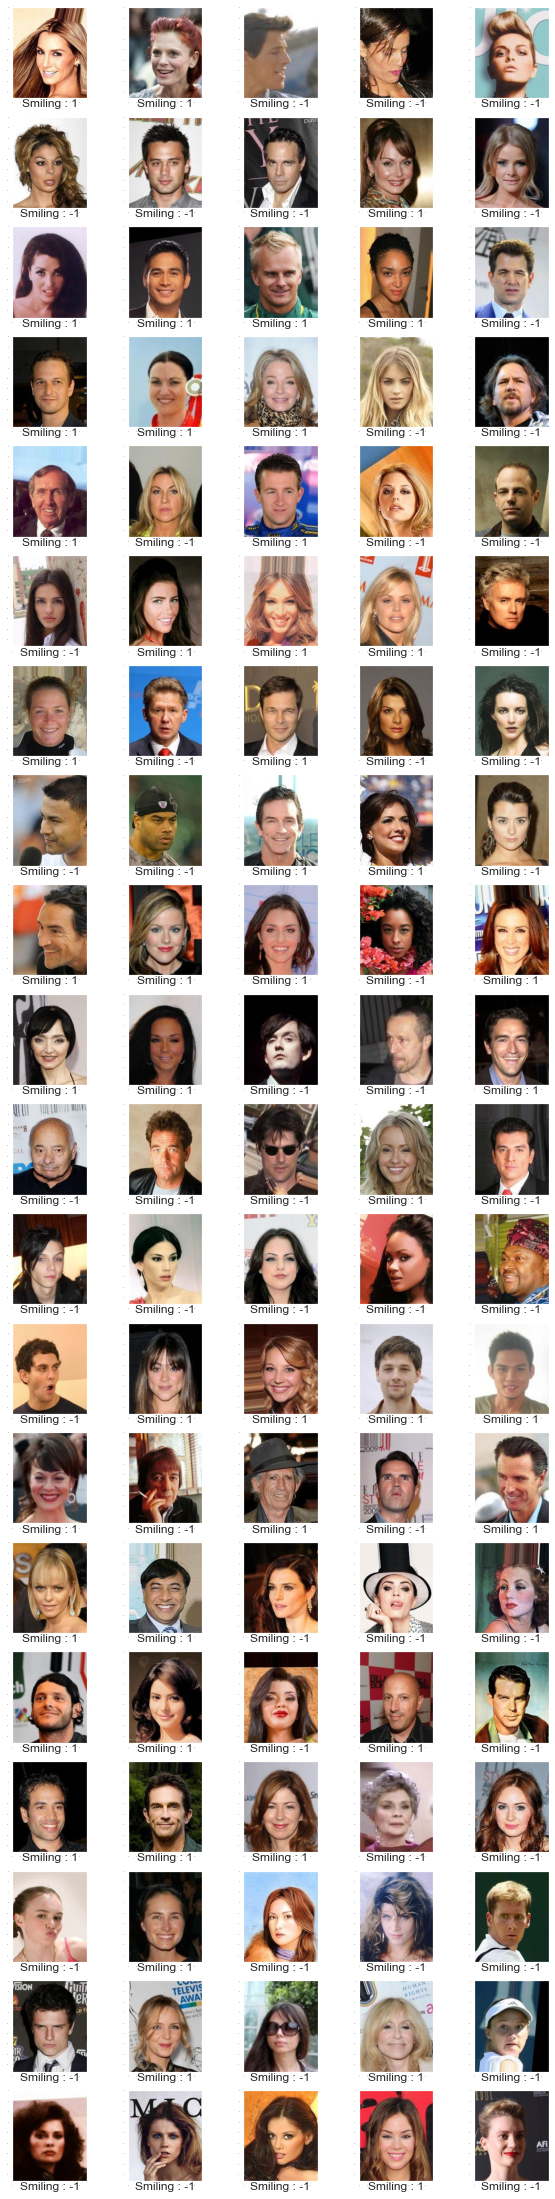

In [7]:
smiling = [f"Smiling : {attributes['Smiling'][img]}" for img in images.index]
image_grid(images.head(100), titles=smiling[:100])

In [2]:
import tensorflow as tf
tf.config.run_functions_eagerly(True)

mobilenet = tf.keras.applications.MobileNet(include_top=False, weights='imagenet', input_shape = (178,218,3))

2022-04-20 06:49:42.068097: I tensorflow/core/platform/cpu_feature_guard.cc:142] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [3]:
mobilenet.summary()

Model: "mobilenet_1.00_224"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_1 (InputLayer)         [(None, 178, 218, 3)]     0         
_________________________________________________________________
conv1 (Conv2D)               (None, 89, 109, 32)       864       
_________________________________________________________________
conv1_bn (BatchNormalization (None, 89, 109, 32)       128       
_________________________________________________________________
conv1_relu (ReLU)            (None, 89, 109, 32)       0         
_________________________________________________________________
conv_dw_1 (DepthwiseConv2D)  (None, 89, 109, 32)       288       
_________________________________________________________________
conv_dw_1_bn (BatchNormaliza (None, 89, 109, 32)       128       
_________________________________________________________________
conv_dw_1_relu (ReLU)        (None, 89, 109, 32)

In [4]:
for layer in mobilenet.layers:
    layer.trainable=False

In [11]:
mobilenet.summary()

Model: "mobilenet_1.00_224"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 178, 218, 3)]     0         
                                                                 
 conv1 (Conv2D)              (None, 89, 109, 32)       864       
                                                                 
 conv1_bn (BatchNormalizatio  (None, 89, 109, 32)      128       
 n)                                                              
                                                                 
 conv1_relu (ReLU)           (None, 89, 109, 32)       0         
                                                                 
 conv_dw_1 (DepthwiseConv2D)  (None, 89, 109, 32)      288       
                                                                 
 conv_dw_1_bn (BatchNormaliz  (None, 89, 109, 32)      128       
 ation)                                         

In [68]:
from tensorflow import keras
from keras.models import Model
from keras.layers import Dense,GlobalAveragePooling2D

myneuralnet = keras.Sequential(
    [
        mobilenet,
        GlobalAveragePooling2D(),
        Dense(64, activation="relu", name="layer1"),
        Dense(64, activation="relu", name="layer2"),
        Dense(2, activation="softmax",name="layer3"),
    ]
)

In [13]:
myneuralnet.build((None,178,218,3))
myneuralnet.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 mobilenet_1.00_224 (Functio  (None, 5, 6, 1024)       3228864   
 nal)                                                            
                                                                 
 global_average_pooling2d (G  (None, 1024)             0         
 lobalAveragePooling2D)                                          
                                                                 
 layer1 (Dense)              (None, 64)                65600     
                                                                 
 layer2 (Dense)              (None, 64)                4160      
                                                                 
 layer3 (Dense)              (None, 2)                 130       
                                                                 
Total params: 3,298,754
Trainable params: 69,890
Non-tra

In [14]:
'''df_clean = images.apply(image_to_series)
df_clean["class"] = attributes['Smiling']
df_clean.to_csv('clean_data.csv')'''

In [11]:
df_clean = pd.read_csv('clean_data.csv', index_col=0)  # chargement du fichier dans le notebook
df_clean

,0,1,2,3,4,5,6,7,8,9,...,116403,116404,116405,116406,116407,116408,116409,116410,116411,class
000001.jpg,253,231,194,253,231,194,253,231,194,253,...,118,49,20,120,50,24,120,50,24,1
000002.jpg,67,52,45,65,50,43,65,50,43,67,...,141,106,100,144,116,112,139,119,112,1
000003.jpg,255,255,255,255,255,255,255,255,255,255,...,94,92,97,95,93,96,94,94,96,-1
000004.jpg,55,46,39,111,102,95,93,86,80,97,...,57,56,52,32,33,28,27,28,23,-1
000005.jpg,152,197,203,150,197,203,150,198,202,149,...,145,199,201,148,199,202,148,199,202,-1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
000995.jpg,216,216,216,216,216,216,216,216,216,217,...,101,75,62,102,74,63,100,72,61,-1
000996.jpg,195,195,197,195,195,197,195,195,197,195,...,140,141,143,140,140,142,139,139,141,1
000997.jpg,254,241,225,254,241,225,254,241,225,254,...,255,212,177,187,143,108,169,125,88,-1
000998.jpg,1,1,1,3,3,3,4,4,4,6,...,65,58,52,70,68,73,71,70,78,-1


In [12]:
X = np.array(df_clean.drop(['class'], axis=1)).reshape((999, 178, 218, 3))

In [13]:
y = np.array(df_clean["class"])
classes = np.unique(y)
class_to_class_number = { cls: number for number, cls in enumerate(classes) }
y_onehot = np.zeros((len(y), len(np.unique(y))))
for i, label in enumerate(y):
    y_onehot[i, class_to_class_number[label]] = 1

In [16]:
opt = keras.optimizers.Adam(learning_rate=0.01)
myneuralnet.compile(loss='categorical_crossentropy', metrics=["accuracy"], optimizer=opt)

In [17]:
test = np.array(y == 1, dtype = int)
X_train = np.concatenate((X[:165], X[333:333+ 79]), axis = 0)
y_train = np.concatenate((y_onehot[:165], y_onehot[333:333+ 79]), axis = 0)

X_test = np.concatenate((X[165:333], X[333+ 79:]), axis = 0)
y_test = np.concatenate((y_onehot[165:333], y_onehot[333+ 79:]), axis = 0)

In [70]:

from sklearn.model_selection import StratifiedKFold
import pdb
stop = pdb.set_trace
def create_model():
    myneuralnet = keras.Sequential(
    [
        mobilenet,
        GlobalAveragePooling2D(),
        Dense(64, activation="relu", name=f"layer1"),
        Dense(64, activation="relu", name=f"layer2"),
        Dense(2, activation="softmax",name=f"layer5"),
    ])
    myneuralnet.build((None,64,64,3))
    opt = keras.optimizers.Adam(learning_rate=0.01)
    myneuralnet.compile(loss='categorical_crossentropy', metrics=["accuracy"], optimizer=opt)
    return myneuralnet


In [69]:


from sklearn.model_selection import StratifiedKFold
import pdb
stop = pdb.set_trace
def create_model():
    myneuralnet = keras.Sequential(
    [
        mobilenet,
        GlobalAveragePooling2D(),
        Dense(64, activation="relu", name=f"layer1"),
        Dense(64, activation="relu", name=f"layer2"),
        Dense(2, activation="softmax",name=f"layer5"),
    ])
    myneuralnet.build((None,64,64,3))
    opt = keras.optimizers.Adam(learning_rate=0.01)
    myneuralnet.compile(loss='categorical_crossentropy', metrics=["accuracy"], optimizer=opt)
    return myneuralnet

def train_evaluate(model, x_train, y_train, x_test, y_test):
    history = model.fit(x_train, y_train, epochs = 10, shuffle = True, batch_size=20)
    return model.evaluate(x_test, y_test)

kFold = StratifiedKFold(n_splits=10)
scores = np.zeros(10)
idx = 0
for train, test in kFold.split(X, y):
    model = create_model()
    scores[idx] = train_evaluate(model, X[train], y_onehot[train], X[test], y_onehot[test])[1]
    idx += 1
print(scores)
print(scores.mean())

Epoch 1/10


C:\Users\rapha\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.9_qbz5n2kfra8p0\LocalCache\local-packages\Python39\site-packages\tensorflow\python\data\ops\structured_function.py:264: UserWarning: Even though the `tf.config.experimental_run_functions_eagerly` option is set, this option does not apply to tf.data functions. To force eager execution of tf.data functions, please use `tf.data.experimental.enable_debug_mode()`.
  warnings.warn(


 3/45 [=>............................] - ETA: 1:22 - loss: 2.6174 - accuracy: 0.5500

KeyboardInterrupt: 

In [20]:
model.save_weights("save")

In [72]:
model.load_weights("save")

In [57]:
predict = model.predict(X)
for i in range(len(y)): 
    print(y[i], end=' : ')
    print(predict[i][1])

1 : 0.9494028
1 : 0.988197
-1 : 0.34709305
-1 : 6.221294e-34
-1 : 0.030820535
-1 : 5.41031e-27
-1 : 0.015313745
-1 : 0.11567957
1 : 0.88773674
-1 : 2.653013e-16
1 : 0.90519506
1 : 0.970794
1 : 0.6282505
1 : 0.48272443
-1 : 1.0207772e-24
1 : 0.2632672
1 : 0.9931063
1 : 0.6488956
-1 : 1.6316881e-10
-1 : 0.0013855142
1 : 0.96800953
-1 : 0.0
1 : 0.6807287
-1 : 0.24911831
-1 : 9.463678e-19
-1 : 6.054254e-17
1 : 0.8803552
1 : 0.9961739
1 : 0.9760525
-1 : 3.309099e-27
1 : 0.93414533
-1 : 4.388841e-37
1 : 0.7287102
-1 : 2.701586e-38
-1 : 0.0
-1 : 0.0054598134
-1 : 0.009382706
1 : 0.861355
1 : 0.5358173
-1 : 3.1961845e-28
1 : 0.7718917
1 : 0.98768485
1 : 0.73313016
-1 : 0.1146279
1 : 0.47028986
1 : 0.58379805
1 : 0.17816228
-1 : 1.804801e-07
-1 : 8.686153e-33
1 : 0.9934104
-1 : 1.8541503e-10
-1 : 0.07083819
-1 : 1.2095955e-35
1 : 0.9974485
-1 : 4.2339285e-23
-1 : 2.6557033e-26
-1 : 0.033390217
-1 : 2.7989167e-29
-1 : 0.006242389
-1 : 0.1259088
-1 : 8.444375e-12
1 : 0.041606497
1 : 0.99699956
1 

In [74]:
error = 0
depart = 500
arrivee = 1000
for i in range(depart,arrivee):
    strimage = f"{i:06d}.jpg"
    test = load_images(dataset_dir, strimage)
    serietest = np.array(test.apply(image_to_series)).reshape((1, 178, 218, 3))
    error += round(model.predict(serietest)[0][1])*2-1 != attributes["Smiling"][strimage]

print("###################", error/(arrivee-depart-1))

C:\Users\rapha\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.9_qbz5n2kfra8p0\LocalCache\local-packages\Python39\site-packages\tensorflow\python\data\ops\structured_function.py:264: UserWarning: Even though the `tf.config.experimental_run_functions_eagerly` option is set, this option does not apply to tf.data functions. To force eager execution of tf.data functions, please use `tf.data.experimental.enable_debug_mode()`.
  warnings.warn(
C:\Users\rapha\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.9_qbz5n2kfra8p0\LocalCache\local-packages\Python39\site-packages\tensorflow\python\data\ops\structured_function.py:264: UserWarning: Even though the `tf.config.experimental_run_functions_eagerly` option is set, this option does not apply to tf.data functions. To force eager execution of tf.data functions, please use `tf.data.experimental.enable_debug_mode()`.
  warnings.warn(
C:\Users\rapha\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.9_qbz5n2kfra8p0\LocalCache

################### 0.09619238476953908


C:\Users\rapha\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.9_qbz5n2kfra8p0\LocalCache\local-packages\Python39\site-packages\tensorflow\python\data\ops\structured_function.py:264: UserWarning: Even though the `tf.config.experimental_run_functions_eagerly` option is set, this option does not apply to tf.data functions. To force eager execution of tf.data functions, please use `tf.data.experimental.enable_debug_mode()`.
  warnings.warn(
